# Model scoringowy

Model został opracowany na danych Give Me Some Credit (z serwisu Kaggle). Celem jest przewidzenie, czy klient w przeciągu najbliższych dwóch lat doświadczy poważnych trudności w spłacie kredytu.
Opracowany model zwraca liczbę punktów scoringowych, jakie klient otrzymał w ramach jednej kategorii w danej zmiennej. Punkty te są wartościami całkowitymi z przedziału $[0,1000]$. Ich suma dla danego klientadaje finalną wartość score, na podstawie której można podjąć decyzję o akceptacji lub odrzuceniu wniosku klienta. Klienci z większym wynikiem score są uznani przez model za mniej ryzykownych.

Model zbudowany jest w oparciu o regresję logistyczną.

### Eksploracyjna analiza danych

Zacznijmy od wczytania danych i zapoznania się z ich strukturą.

In [244]:
import pandas as pd

dane = pd.read_csv("C:/Users/olako/OneDrive/Pulpit/bankowość/cs-training.csv")
dane.shape

(150000, 12)

Dostępne dane zawierają łącznie 150 tys. obserwacji. Każdą z nich opisuje 12 kolumn. Przyjrzyjmy się, co oznaczają dane kolumny.

In [245]:
dane.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


Kolumna Unnamed prawdopodobnie nie pochodzi z oryginalnych danych i jest jedynie indeksem tabeli. Możemy ją zatem od razu usunąć, ponieważ nie zawiera żadnej informacji potrzebnej przy modelu.

In [246]:
dane.drop("Unnamed: 0", axis=1, inplace=True)

In [247]:
dane.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtype

Opiszmy pozostałe kolumny:
1. SeriousDlqin2yrs - zmienna docelowa (target) - przyjmuje wartości binarne:
    - 1 – klient doświadczył opóźnienia w spłacie zobowiązań o 90 dni lub więcej w ciągu ostatnich dwóch lat  
    - 0 – brak opóźnień tego typu

2. RevolvingUtilizationOfUnsecuredLines - stosunek całkowitego salda na kartach kredytowych i liniach kredytowych (z wyłączeniem nieruchomości i kredytów ratalnych) do sumy dostępnych limitów kredytowych,

3. age - wiek kredytobiorcy (w latach),

4. NumberOfTime30-59DaysPastDueNotWorse - liczba sytuacji, w których kredytobiorca miał opóźnienie w spłacie od 30 do 59 dni w ciągu ostatnich dwóch lat,

5. DebtRatio - stosunek miesięcznych zobowiązań finansowych do miesięcznego dochodu brutto,

6. MonthlyIncome - deklarowany miesięczny dochód kredytobiorcy,

7. NumberOfOpenCreditLinesAndLoans - liczba otwartych kredytów ratalnych i linii kredytowych (np. karty kredytowe),

8. NumberOfTimes90DaysLate - liczba sytuacji, w których kredytobiorca miał opóźnienie w spłacie o 90 dni lub więcej,

9. NumberRealEstateLoansOrLines - liczba kredytów hipotecznych i innych kredytów związanych z nieruchomościami,

10. NumberOfTime60-89DaysPastDueNotWorse - liczba sytuacji, w których kredytobiorca miał opóźnienia w spłacie od 60 do 89 dni,

11. NumberOfDependents - liczba osób na utrzymaniu kredytobiorcy (np. małżonek, dzieci).


Przyjrzyjmy się dokładniej stosunkowi liczby targetów - dla nas będą to kredytobiorcy z problemami w spłacie przez więcej niż 89 dni - do pozostałych klientów. 

In [248]:
dane.SeriousDlqin2yrs.value_counts(dropna=True)

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Widzimy, że jest ich około 10 tys. na 150 tys. wszystkich klientów. Stanowią oni zatem mniej niż 7% obserwacji. Możemy także zauważyć, że w kolumna SeriousDlqin2yrs nie zawiera wartości NaN. Oznacza to, że nie mamy braków w informacji o targetach.

Spójrzmy na pozostałe zmienne i sprawdźmy, czy dane nie zawierają błędów (braki danych, duplikaty) lub znacznej liczby wartości odstających. Trzeba zdecydować, co zrobić w przypadku ich wystąpienia.

In [249]:
dane.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


Zwróćmy uwagę, że w kolumnie wiek wartość minimalna jest równa 0. Sugeruje to błąd w danych. Sprawdźmy, ile klientów ma mniej niż 18 i 21 lat.

In [250]:
(dane.age<18).value_counts()

age
False    149999
True          1
Name: count, dtype: int64

In [251]:
(dane.age<21).value_counts()

age
False    149999
True          1
Name: count, dtype: int64

Widzimy, że jest tylko jedna wartość poniżej 21 r. ż. zatem jest to zaobserwowana wartość minimalna (równa 0). Chcemy wykluczyć te obserwacje z danych. Możemy sobie na to pozwolić, ponieważ jest to tylko jedna obserwacja.

In [252]:
dane = dane.query('age >= 18').reset_index(drop=True)

Możemy zauważyć, że również maksymalna wartość wieku jest podejrzana, wynosi 109 lat. Jest ona mało prawdopodobna, ale możliwa. Wszystkie takie wartości pozostawiamy bez zmian.

Kolejnym krokiem jest sprawdzenie liczby brakujących wartości (NaN) dla każdej z kolumn.

In [253]:
dane.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

Wartości NaN pojawiają się jedynie przy dwóch zmiennych. Moglibyśmy uzupełnić je w sposób sztuczny (np. średnią z danej zmiennej), jednak sprawiłoby to, że model wyuczy się na danych nieprawdziwych. Jednocześnie usunięcie takiej liczby obserwacji jest już bardziej kosztowne dla modelu. Dlatego zostawimy te wartości, pamiętając, że dalszy kod powinien je obsługiwać.

Dalej sprawdzimy liczbę duplikatów.

In [254]:
print(dane.shape[0] - dane.drop_duplicates().shape[0])

609


Dane nie zawierają wiele duplikatów. Ze względu na brak identyfikatorów trudno jest powiedzieć, czy te obserwacje dotyczą dokładnie tego samego klienta, czy mamy te same wartości zmiennych dla kilku kredytobiorców. Możemy sobie jednak pozwolić na wyjęcie z analizy duplikatów zakładając, że z jednakowe obserwacje nie dadzą nam nowych informacji.

In [255]:
dane.drop_duplicates(inplace=True)

Resztę danych pozostawiamy bez zmian.

In [256]:
print(dane.shape)
dane.head()

(149390, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


Dalej podzielimy dane na treningowe i testowe w proporcji 70:30. Przyjrzyjmy się ich rozkładom. Powinny być one podobne - w przeciwnym razie możemy się spodziewać, że model nie będzie działał dobrze na danych testowych.

In [257]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(dane[[i for i in dane.columns if i != 'SeriousDlqin2yrs']], dane['SeriousDlqin2yrs'], test_size=0.3, random_state=42)

Poniżej tworzymy wykresy dla każdej zmiennej na zbiorze treningowym i testowym. Po prawej stronie otrzymujemy histogram dla danej zmiennej, a po lewej wykres przedstawiający średnią wartość zmiennej docelowej dla oberwacji z odpowiedniego przedziału histogramu.

Porównanie rozkładów zbioru treningowego i testowego jest dokonane automatycznie - przy wykresie dla zbioru testowego jest podana korelacja trendów z obu wykresów. Przyjmuje ona wartości bliskie 100%, co daje nam poczucie, że podział ten jest odpowiedni.

W dalszej części pracy będziemy dokonywać także wyboru zmiennych znaczących. Możemy zatem od razu zwrócić uwagę na zachowanie wykresów. Najlepsze dla modelu będą zmienne zachowujące liniowy kształt (monotoniczność) na wykresie z lewej strony. Jednocześnie możemy zauważyć, które zmienne dają największy rozstrzał między wartościami średnich ze zmiennej docelowej - potencjalnie to one najlepiej rozróżniają klientów będących targetami.
Chcielibyśmy także, żeby rozkład widoczny na histogramach był jednostajny (lub bliski jednostajnemu) i aby słupki histogramu zachowywały podobne szerokości.
Należy jednak pamiętać, że w rzeczywistości nie jesteśmy w stanie zapewnić sobie wszystkich tych własności.

                            Plots for RevolvingUtilizationOfUnsecuredLines                            
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

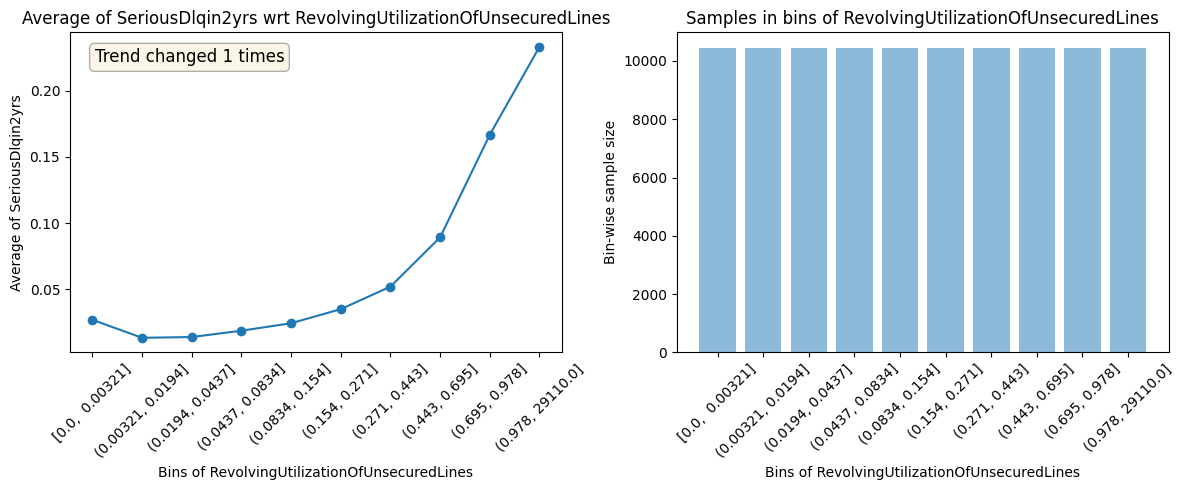

                                           Test data plots                                            


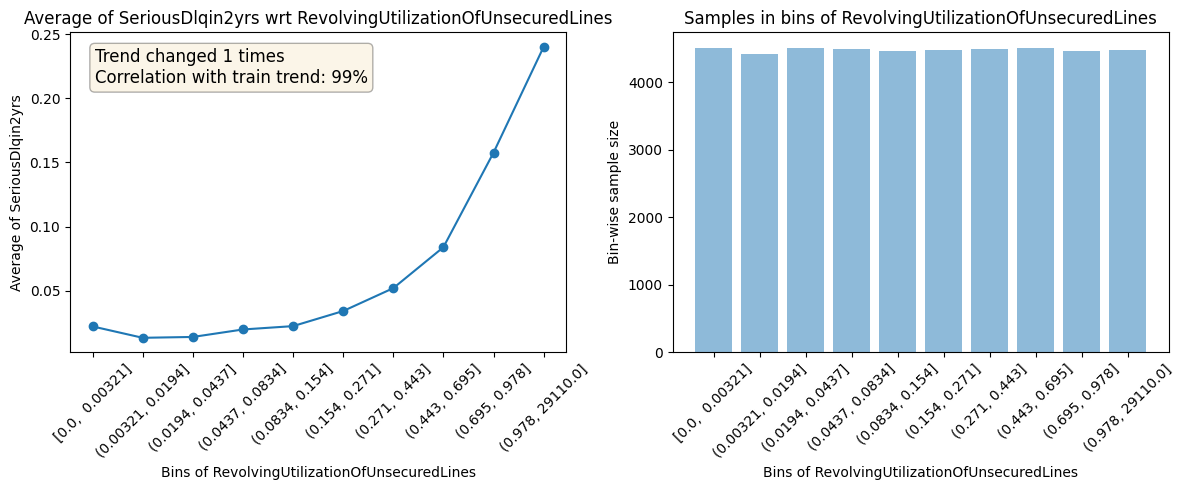

--------------------------------------------------------------------------------------------------------------


                                            Plots for age                                             
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

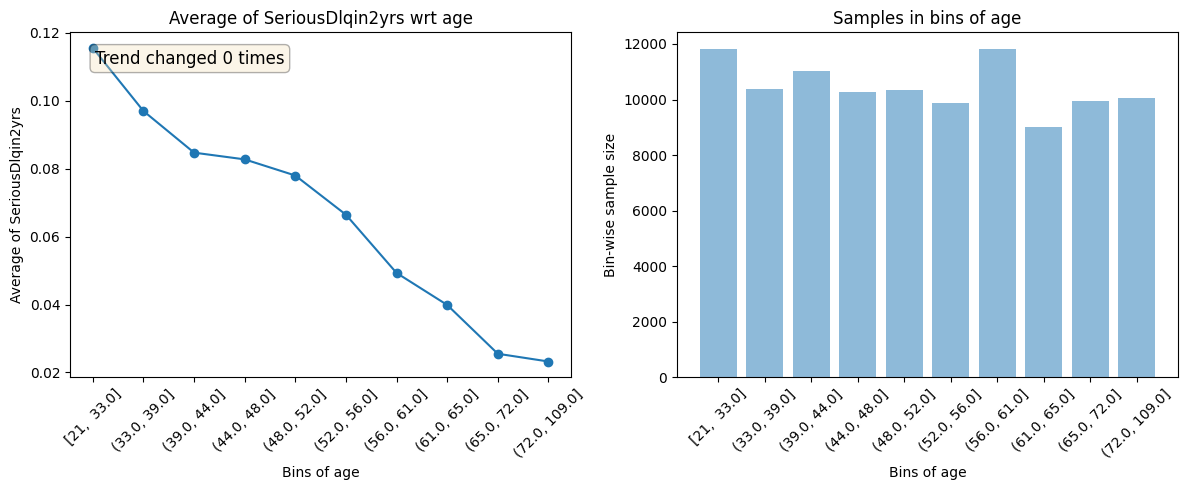

                                           Test data plots                                            


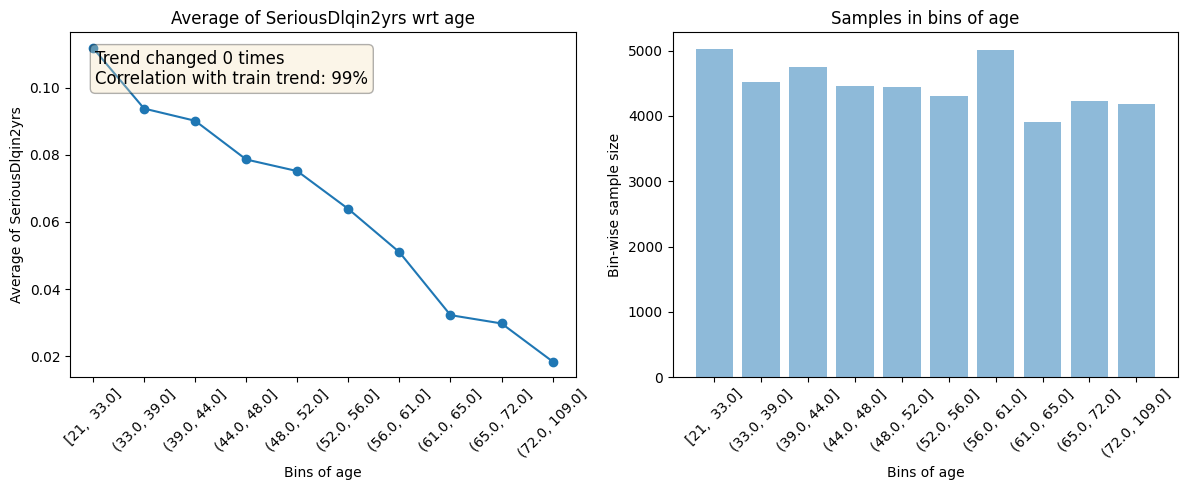

--------------------------------------------------------------------------------------------------------------


                            Plots for NumberOfTime30-59DaysPastDueNotWorse                            
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

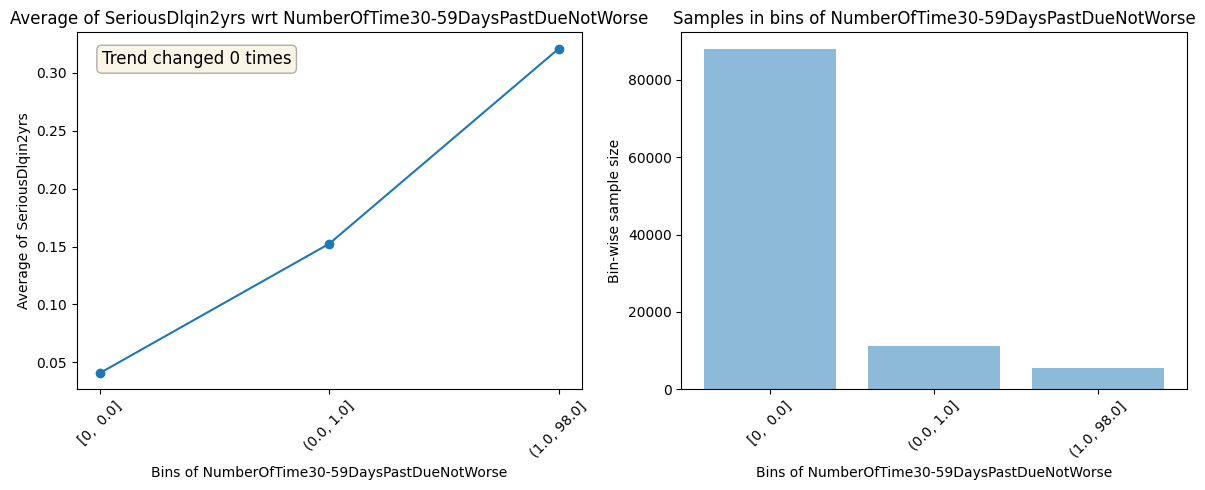

                                           Test data plots                                            


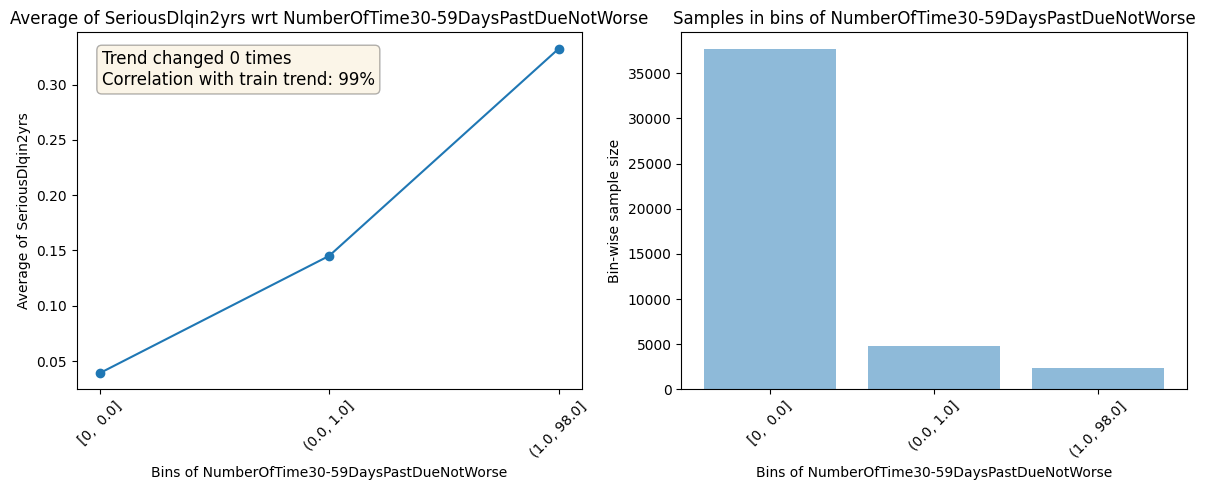

--------------------------------------------------------------------------------------------------------------


                                         Plots for DebtRatio                                          
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

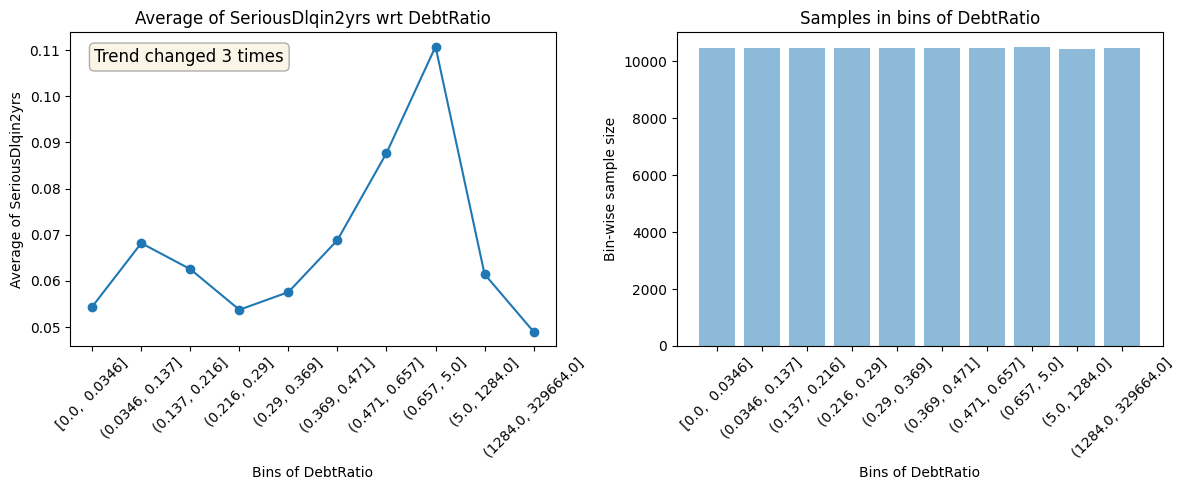

                                           Test data plots                                            


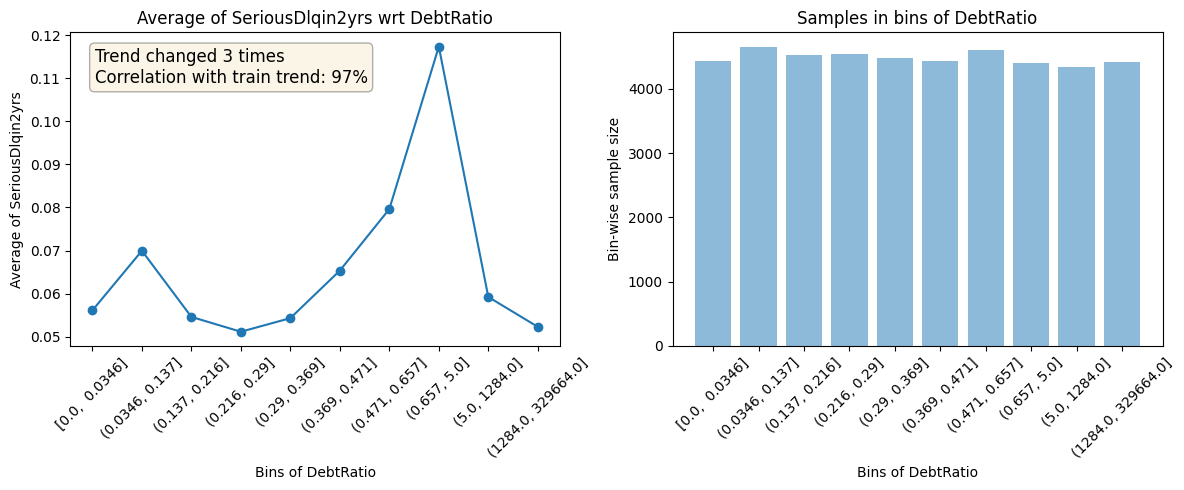

--------------------------------------------------------------------------------------------------------------


                                       Plots for MonthlyIncome                                        
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

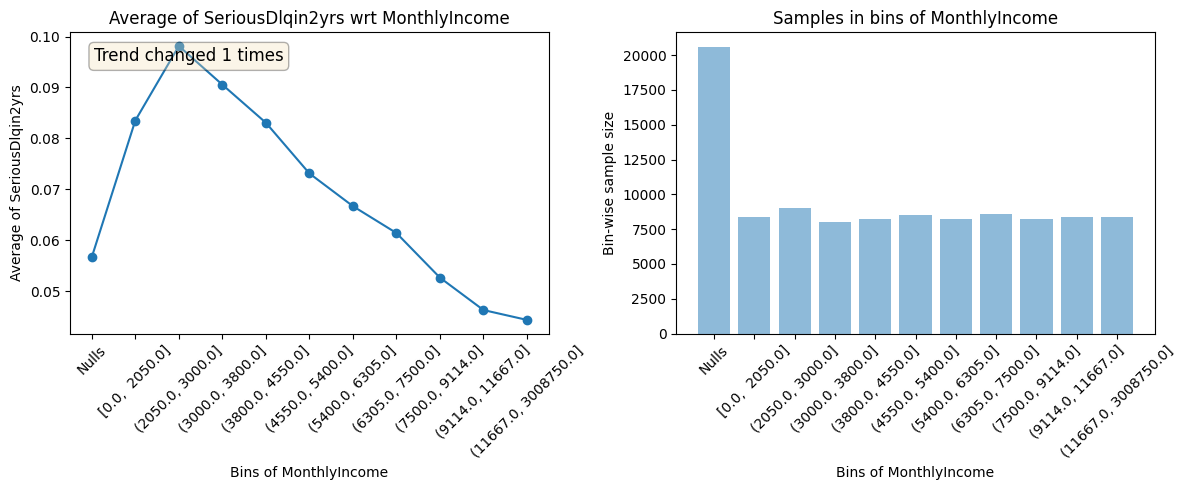

                                           Test data plots                                            


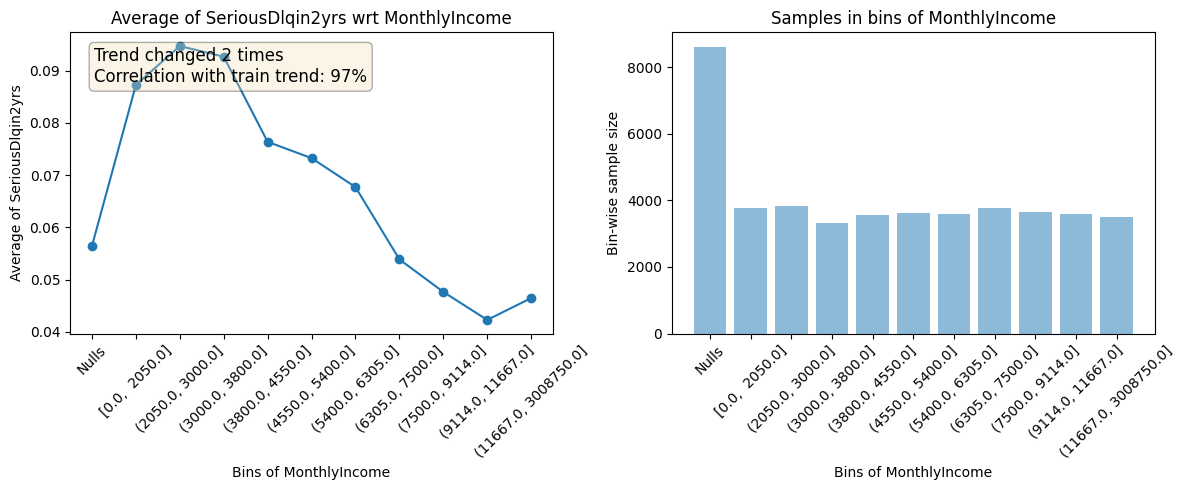

--------------------------------------------------------------------------------------------------------------


                              Plots for NumberOfOpenCreditLinesAndLoans                               
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

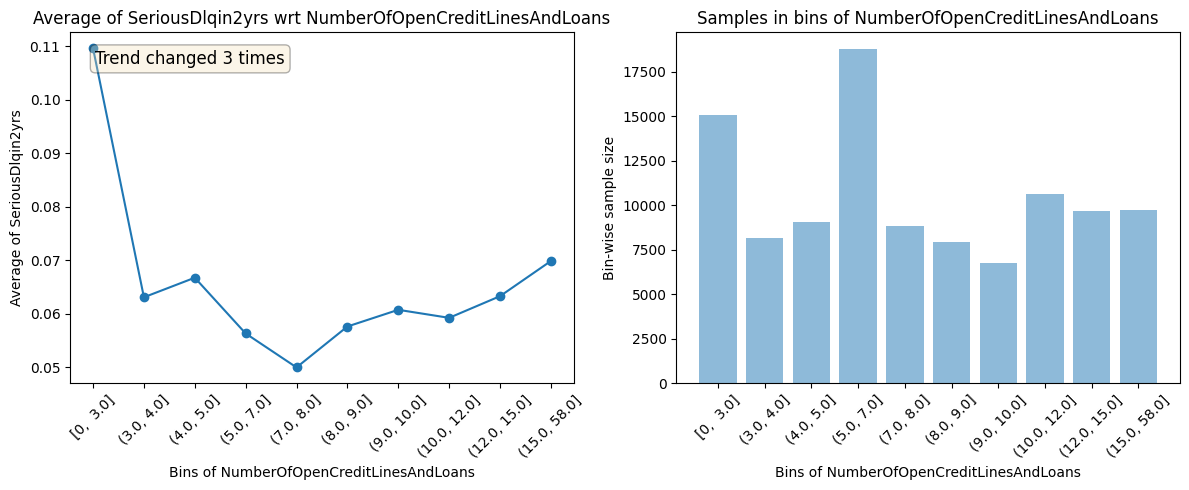

                                           Test data plots                                            


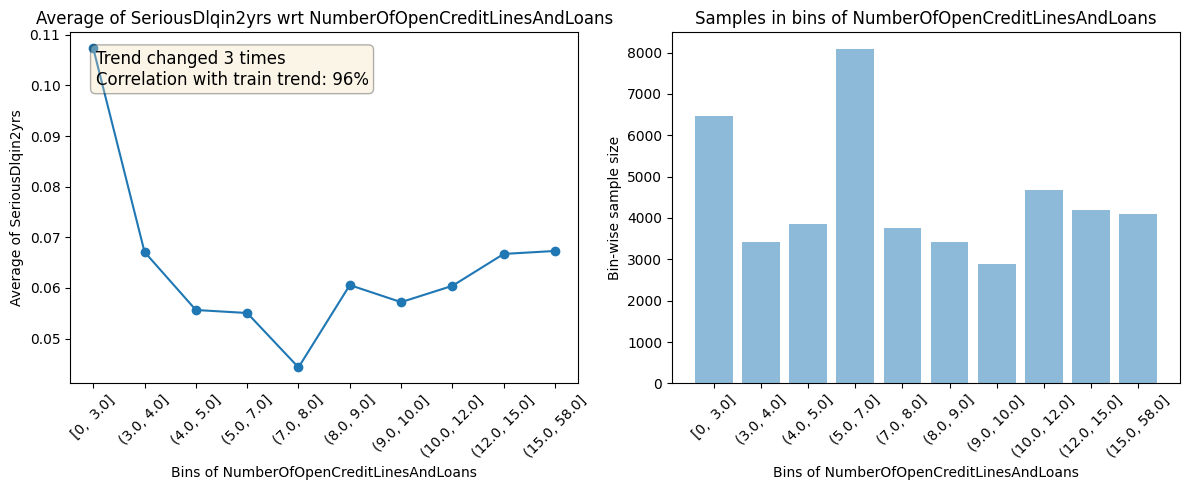

--------------------------------------------------------------------------------------------------------------


                                  Plots for NumberOfTimes90DaysLate                                   
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

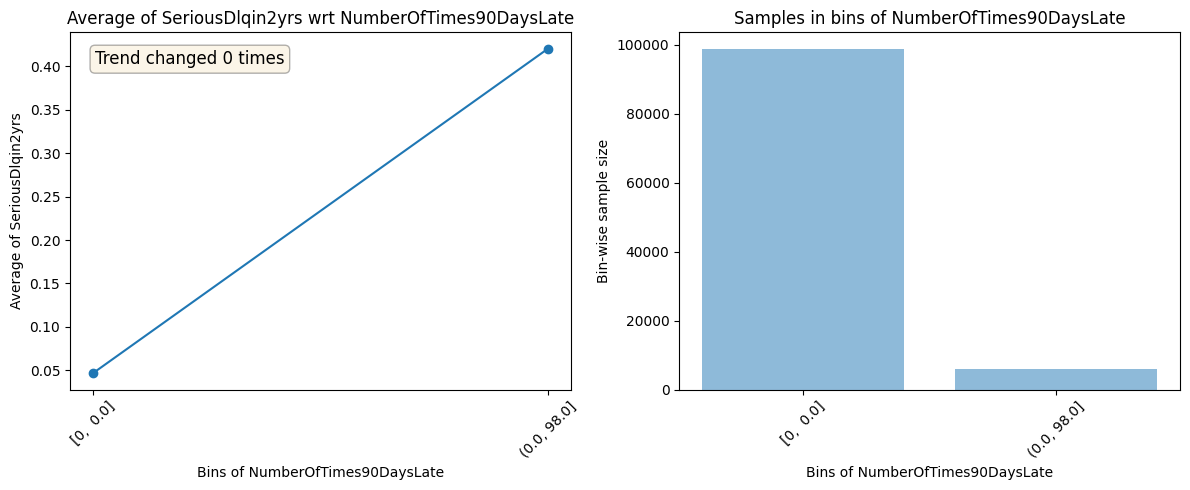

                                           Test data plots                                            


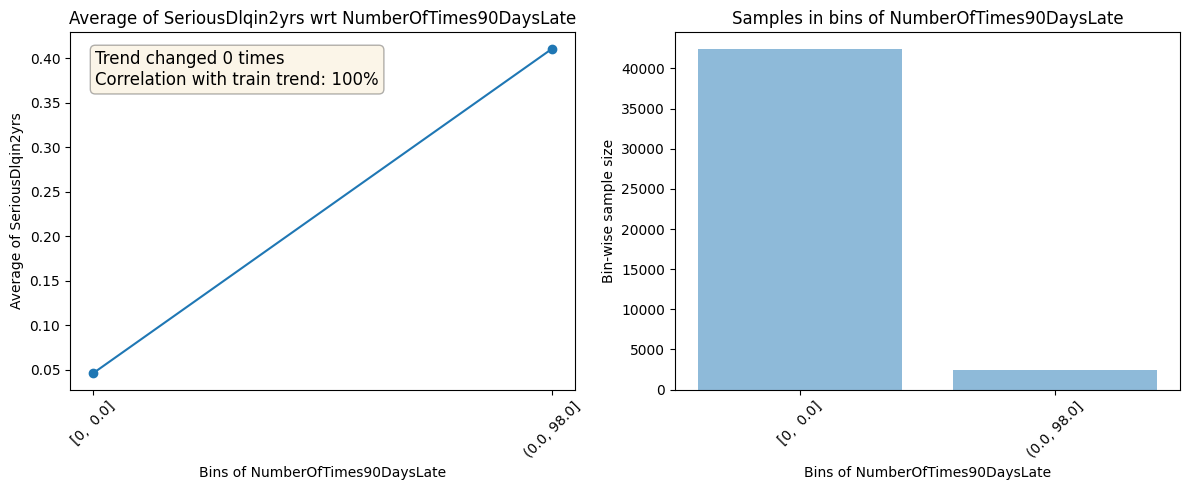

--------------------------------------------------------------------------------------------------------------


                                Plots for NumberRealEstateLoansOrLines                                
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

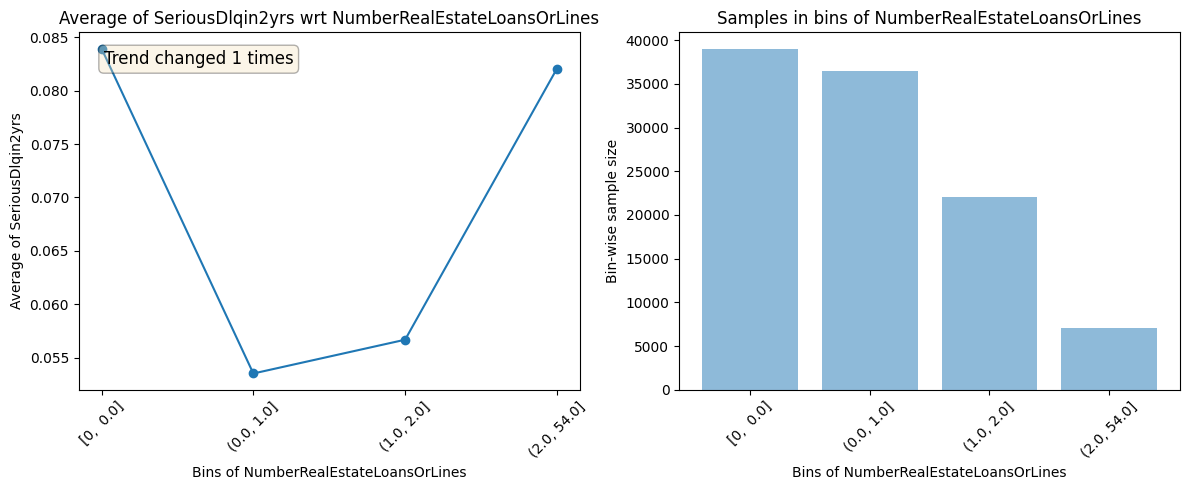

                                           Test data plots                                            


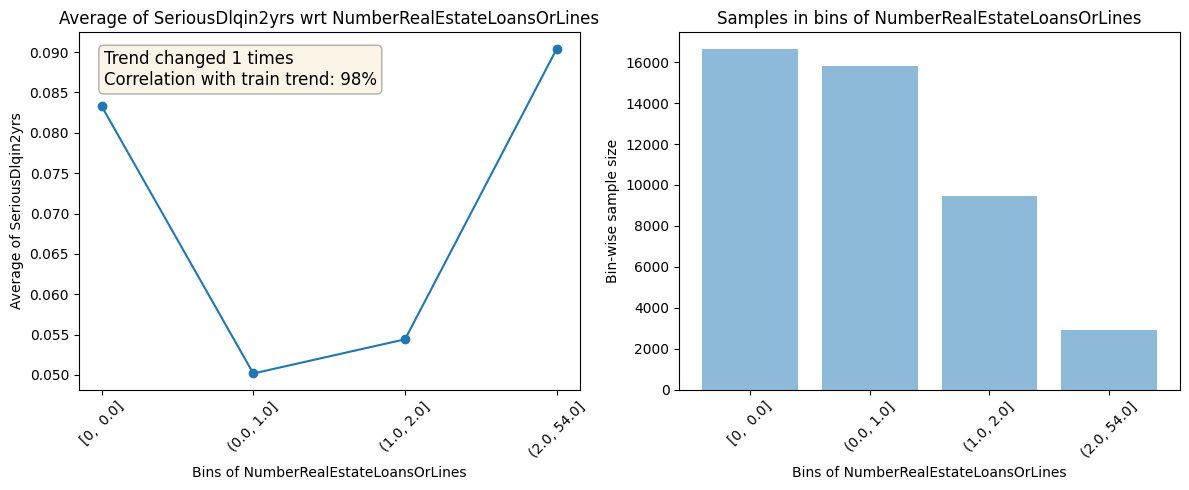

--------------------------------------------------------------------------------------------------------------


                            Plots for NumberOfTime60-89DaysPastDueNotWorse                            
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

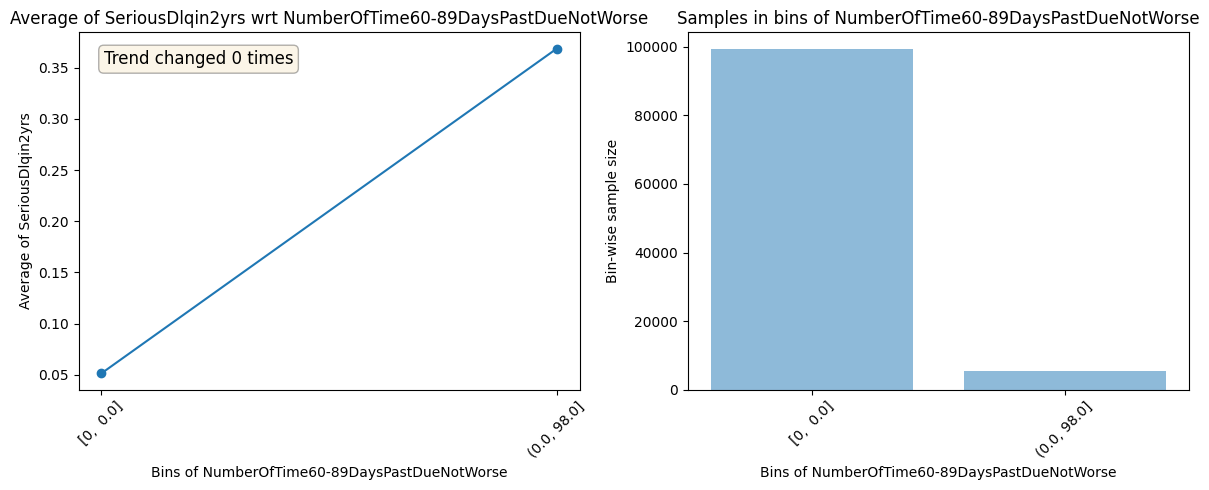

                                           Test data plots                                            


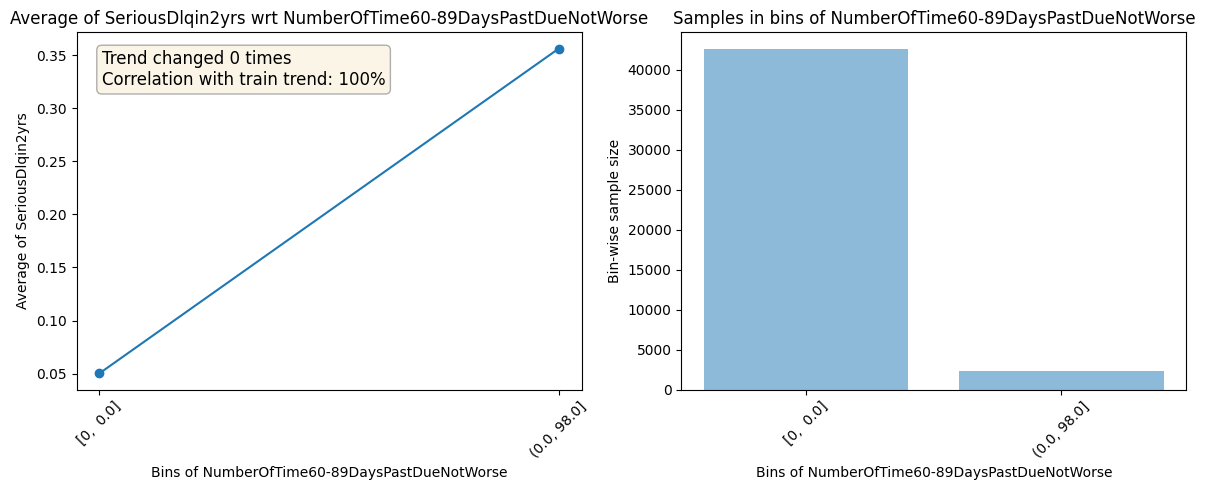

--------------------------------------------------------------------------------------------------------------


                                     Plots for NumberOfDependents                                     
                                           Train data plots                                           


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The provided callable <function mean at 0x000002A735FBDEE0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grouped = input_data.groupby([cut_series], as_index=True).agg(
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\featexp\base.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version o

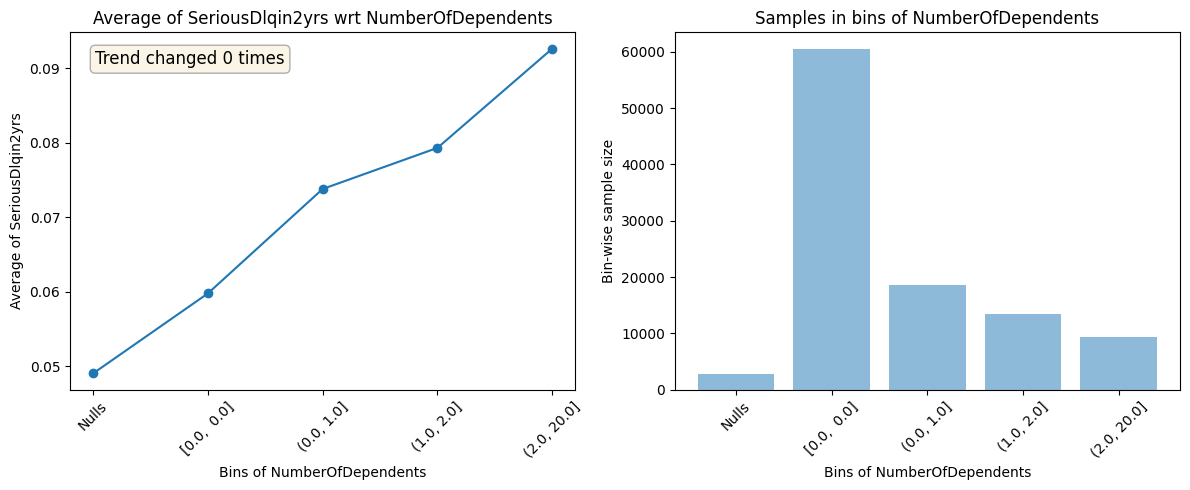

                                           Test data plots                                            


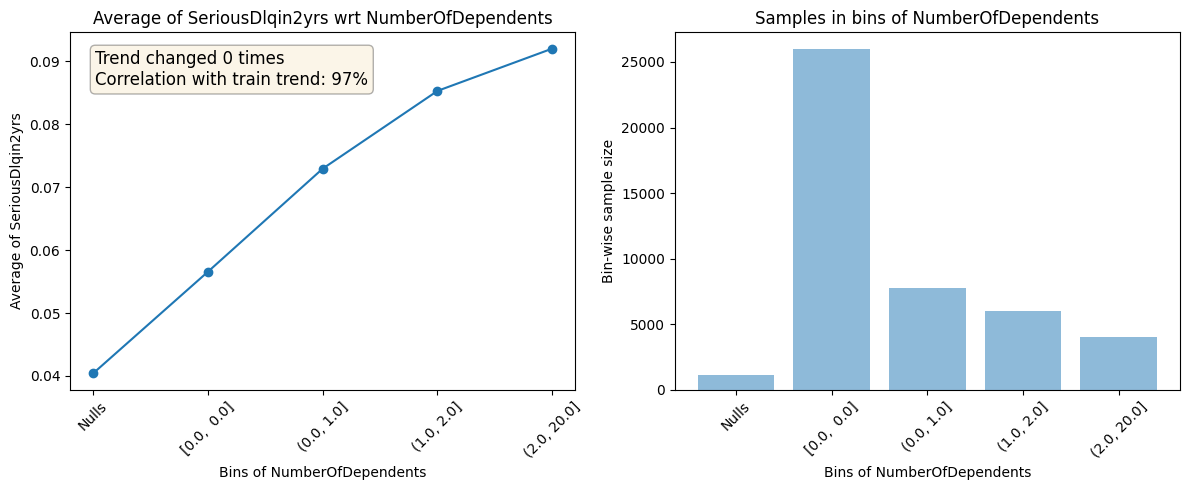

--------------------------------------------------------------------------------------------------------------




In [258]:
from featexp import get_univariate_plots

get_univariate_plots(data=X_train.merge(y_train, left_index=True, right_index=True, how='left'),
                     target_col='SeriousDlqin2yrs',
                     data_test=X_test.merge(y_test, left_index=True, right_index=True, how='left'))

Po przeanalizowaniu powyższych wykresów, wyodrębnijmy te zmienne, dla których wykres średniej z liczby targetów (dla ustalonego na widocznym histogramie podziału na binsy) zachowuje monotoniczność lub jest bliski takiemu trendowi. 
Są to zmienne: 
- age, 
- NumberOfTime30-59DaysPastDueNotWorse, 
- NumberOfTimes90DaysLate, 
- NumberOfTime60-89DaysPastDueNotWorse, 
- NumberOfDependents.

Przy czym zmienne należy zauważyć, że zmienne opisujące liczbę dni opóźnienia są podzielone jedynie na dwie lub trzy grupy (binsy). Jednocześnie liczność i szerokość przedziałek na histogramach tych zmiennych jest mocno nierównomierna. Okazuje się, że przeważająca większość kredytobiorców osiąga 0 dni opóźnienia. Jest to zgodne z intuicją, że większość klientów nie doświadcza problemów w spłacie - co widać także przy spojrzeniu na zmienną docelową. Możemy jednak przypuszczać, że informacja o liczbie dni opóźnienia może być mimo wszystko istotna w modelu. Widać to także, po spojrzeniu na pionową oś wykresu - rozstrzał między średnią ze zmiennej docelowej dla osobnych binsów jest największy właśnie dla tych zmiennych i różnica ta osiąga wartość ok. 0.3-0.4. Dla porównania ta sama różnica dla zmiennej age wynosi 0.08, a dla NumberOfDependents: 0.05.
Podział na binsy w histogramach dla zmiennej age jest mniej więcej równomierny, a dla zmienna NumberOfDependents nierównomierny, choć nie aż tak widocznie, jak w przypadku zmiennych związanych z liczbą dni opóźnienia.

Zmienna RevolvingUtilizationOfUnsecuredLines ma dobry podział na binsy w histogramach i wykres, który możnaby próbować poprawić na bardziej liniowy zmianą podziałów na słupki w histogramach. Pozostałe zmiennej mają bardziej odczuwalne zmiany w trendach na wykresach ze średnią ze zmiennej docelowej. 
Najsłabiej wypadają:
- DebtRatio,
- NumberOfOpenCreditLinesAndLoans,
- NumberRealEstateLoansOrLines.

Choć większość z nich ma lepszy podział na binsy w histogramach niż pierwsza opisana grupa zmiennych.


Zapoznaliśmy się już z rozkładami zmiennych. Spójrzmy jeszcze na korelacje między nimi.

In [259]:
def color(value):
    if abs(value) <= 0.5:
        color =  'green'
    elif abs(value) <= 0.9:
        color = 'orange'
    elif abs(value) > 0.9:
        color = 'red'
    else:
        color = 'blue'
    return f'color: {color}'.format(color)

In [260]:
X_train.corr(method='pearson').style.applymap(color)

C:\Users\olako\AppData\Local\Temp\ipykernel_22188\314435035.py:1: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  X_train.corr(method='pearson').style.applymap(color)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
RevolvingUtilizationOfUnsecuredLines,1.000000,-0.007254,-0.001704,0.004347,0.004333,-0.012249,-0.001303,0.005915,-0.001040,0.000880
age,-0.007254,1.000000,-0.053148,0.024265,0.034814,0.146603,-0.051648,0.032516,-0.047069,-0.216264
NumberOfTime30-59DaysPastDueNotWorse,-0.001704,-0.053148,1.000000,-0.005377,-0.009957,-0.047710,0.980000,-0.026840,0.984343,0.002330
DebtRatio,0.004347,0.024265,-0.005377,1.000000,-0.026128,0.046932,-0.007570,0.118902,-0.006750,-0.038903
MonthlyIncome,0.004333,0.034814,-0.009957,-0.026128,1.000000,0.087137,-0.012057,0.122736,-0.010413,0.064073
NumberOfOpenCreditLinesAndLoans,-0.012249,0.146603,-0.047710,0.046932,0.087137,1.000000,-0.074759,0.432982,-0.064936,0.061705
NumberOfTimes90DaysLate,-0.001303,-0.051648,0.980000,-0.007570,-0.012057,-0.074759,1.000000,-0.042324,0.991134,-0.005164
NumberRealEstateLoansOrLines,0.005915,0.032516,-0.026840,0.118902,0.122736,0.432982,-0.042324,1.000000,-0.036157,0.122727
NumberOfTime60-89DaysPastDueNotWorse,-0.001040,-0.047069,0.984343,-0.006750,-0.010413,-0.064936,0.991134,-0.036157,1.000000,-0.005835
NumberOfDependents,0.000880,-0.216264,0.002330,-0.038903,0.064073,0.061705,-0.005164,0.122727,-0.005835,1.000000


Zgodnie z intuicją występuje wysoka korelacja dla zmiennych dotyczących opóźnienia w spłacie zobowiązań. Mierzą one podobne zachowania klientów, a klienci, którzy spóźnili się ze spłatą o 60-89 dni, musieli wcześniej spóźnić się o 30-59 dni ze spłatą.

Korelacja między tymi zmiennymi nie musi automatycznie ich dyskredytować. Istnieje szansa, że każda zmienna dodaje pewne nowe informacje dla modelu. Wymaga to dalszej analizy.

Pozostałe zmienne charakteryzują się niską korelacją.

### Wybór zmiennych znaczących
Po pierwszej analizie zmiennych opisowych rozpoczynamy poszukiwanie najlepszych zmiennych do zbudowania na nich modelu scoringowego. Chcemy zatem znaleźć takie zmienne, które najlepiej rozróżniają klientów względem zmiennej docelowej.

Zaczniemy od utworzenia wartości WoE dla odpowiednio podzielonych bucketów dla każdej zmiennej. Wartość ta służy bezpośrednio to utworzenia modelu regresji logistycznej.

#### Wartości WoE

Sprawdzimy wartości WoE (Weight of Evidence) dla każdej ze zmiennych po podziale na odpowiednie buckety. Aby zmienne były miarodajne, żaden z bucketów nie może zawierać mniej niż 5% obserwacji.

Wartość WoE określa stosunek liczby klientów "dobrych" i "złych" w danej kategorii. Miarę tą wyznacza poniższy wzór:
$$
\text{WoE} = \ln\left( \frac{\% \text{good}}{\% \text{bad}} \right)
$$

Wartość WoE powyżej 0 oznacza zwiększony udział "dobrych" klientów, a poniżej 0 zwiększony udział "złych" klientów. WoE jest potrzebne do zbudowania modelu regresji logistycznej - odpowiada ono funkcji logit.

Poniżej wykorzystamy funkcje, która od razu dzieli zmienne na buckety tak, aby zawierały one zawsze powyżej 5% obserwacji i wylicza dla nich wartości WoE.

In [261]:
import scorecardpy as sc

In [262]:
bins = sc.woebin(X_train.merge(y_train, left_index=True, right_index=True, how="left"), y = 'SeriousDlqin2yrs')

[INFO] creating woe binning ...


c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\scorecardpy\condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\scorecardpy\condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
c:\Users\olako\AppData\Local\Programs\Python\Python312\Lib\site-packages\scorecardpy\woebin.py:320: FutureWarning: The default of observe

Wyświetlmy wynik funkcji w tabeli. Możemy z niej odczytać:
- jaki został dobrany podział na buckety (bin) oraz ich liczność (count) i procent (count_distr),
- liczbość i procent goodów oraz badów (good, bad, badprob),
- wartości woe dla danego bucketu (woe),
- wartości IV (bin_iv, total_iv) - będą opisane szerzej w dalszej części raportu,
- czy dany bucket zawiera wartości specjalne, np. NaN (is_special_values).

In [263]:
for i in bins.keys():
    display(bins[i])

,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,NumberRealEstateLoansOrLines,"[-inf,1.0)",38957,0.372534,35687,3270,0.083939,0.236760,0.023145,0.052185,1.0,False
1,NumberRealEstateLoansOrLines,"[1.0,2.0)",36534,0.349364,34579,1955,0.053512,-0.246100,0.019037,0.052185,2.0,False
2,NumberRealEstateLoansOrLines,"[2.0,3.0)",22038,0.210743,20789,1249,0.056675,-0.185324,0.006683,0.052185,3.0,False
3,NumberRealEstateLoansOrLines,"[3.0,inf)",7044,0.067360,6466,578,0.082056,0.212017,0.003320,0.052185,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,DebtRatio,"[-inf,0.4)",55864,0.534211,52537,3327,0.059555,-0.132690,0.008883,0.067394,0.4,False
1,DebtRatio,"[0.4,0.5)",9204,0.088015,8531,673,0.073120,0.087040,0.000692,0.067394,0.5,False
2,DebtRatio,"[0.5,0.65)",7844,0.075010,7139,705,0.089878,0.311626,0.008341,0.067394,0.65,False
3,DebtRatio,"[0.65,2.6500000000000004)",10128,0.096851,8974,1154,0.113942,0.575659,0.041229,0.067394,2.6500000000000004,False
4,DebtRatio,"[2.6500000000000004,inf)",21533,0.205914,20340,1193,0.055403,-0.209362,0.008249,0.067394,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,NumberOfDependents,missing,2714,0.025953,2581,133,0.049005,-0.338827,0.002577,0.030059,missing,True
1,NumberOfDependents,"[-inf,1.0)",60429,0.577864,56818,3611,0.059756,-0.129112,0.009111,0.030059,1.0,False
2,NumberOfDependents,"[1.0,2.0)",18566,0.177541,17196,1370,0.073791,0.096890,0.001738,0.030059,2.0,False
3,NumberOfDependents,"[2.0,3.0)",13528,0.129364,12455,1073,0.079317,0.175093,0.004279,0.030059,3.0,False
4,NumberOfDependents,"[3.0,inf)",9336,0.089277,8471,865,0.092652,0.345082,0.012353,0.030059,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,NumberOfTime60-89DaysPastDueNotWorse,"[-inf,1.0)",99299,0.949566,94192,5107,0.051431,-0.287967,0.069593,0.57453,1.0,False
1,NumberOfTime60-89DaysPastDueNotWorse,"[1.0,inf)",5274,0.050434,3329,1945,0.368790,2.089346,0.504937,0.57453,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,RevolvingUtilizationOfUnsecuredLines,"[-inf,0.1)",44885,0.429222,44059,826,0.018403,-1.349934,0.451769,1.064751,0.1,False
1,RevolvingUtilizationOfUnsecuredLines,"[0.1,0.4)",25991,0.248544,25039,952,0.036628,-0.642868,0.078274,1.064751,0.4,False
2,RevolvingUtilizationOfUnsecuredLines,"[0.4,0.75)",14644,0.140036,13309,1335,0.091164,0.327247,0.017290,1.064751,0.75,False
3,RevolvingUtilizationOfUnsecuredLines,"[0.75,inf)",19053,0.182198,15114,3939,0.206739,1.282062,0.517418,1.064751,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,NumberOfTime30-59DaysPastDueNotWorse,"[-inf,1.0)",87802,0.839624,84237,3565,0.040603,-0.535714,0.191921,0.724047,1.0,False
1,NumberOfTime30-59DaysPastDueNotWorse,"[1.0,2.0)",11251,0.107590,9536,1715,0.152431,0.911095,0.132482,0.724047,2.0,False
2,NumberOfTime30-59DaysPastDueNotWorse,"[2.0,inf)",5520,0.052786,3748,1772,0.321014,1.877643,0.399644,0.724047,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,NumberOfOpenCreditLinesAndLoans,"[-inf,3.0)",8753,0.083702,7589,1164,0.132983,0.751919,0.065598,0.07842,3.0,False
1,NumberOfOpenCreditLinesAndLoans,"[3.0,15.0)",83552,0.798983,78549,5003,0.059879,-0.126928,0.012187,0.07842,15.0,False
2,NumberOfOpenCreditLinesAndLoans,"[15.0,inf)",12268,0.117315,11383,885,0.072139,0.072468,0.000636,0.07842,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,MonthlyIncome,missing,20610,0.197087,19442,1168,0.056672,-0.185386,0.006254,0.069469,missing,True
1,MonthlyIncome,"[-inf,4000.0)",26714,0.255458,24287,2427,0.090851,0.323471,0.030767,0.069469,4000.0,False
2,MonthlyIncome,"[4000.0,5500.0)",16158,0.154514,14909,1249,0.077299,0.147135,0.003566,0.069469,5500.0,False
3,MonthlyIncome,"[5500.0,10000.0)",27154,0.259665,25549,1605,0.059107,-0.140718,0.004839,0.069469,10000.0,False
4,MonthlyIncome,"[10000.0,inf)",13937,0.133275,13334,603,0.043266,-0.469399,0.024043,0.069469,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,NumberOfTimes90DaysLate,"[-inf,1.0)",98725,0.944077,94132,4593,0.046523,-0.393408,0.123508,0.847455,1.0,False
1,NumberOfTimes90DaysLate,"[1.0,inf)",5848,0.055923,3389,2459,0.420486,2.305976,0.723947,0.847455,inf,False


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,age,"[-inf,40.0)",22198,0.212273,19825,2373,0.106902,0.503968,0.067134,0.248132,40.0,False
1,age,"[40.0,56.0)",39041,0.373337,35937,3104,0.079506,0.177681,0.012731,0.248132,56.0,False
2,age,"[56.0,66.0)",23334,0.223136,22246,1088,0.046627,-0.391065,0.028873,0.248132,66.0,False
3,age,"[66.0,inf)",20000,0.191254,19513,487,0.024350,-1.063816,0.139394,0.248132,inf,False


Wyciągnijmy same wartości WoE i informacje o bucketach.

In [264]:
train_woe = sc.woebin_ply(X_train, bins)

[INFO] converting into woe values ...


In [265]:
test_woe = sc.woebin_ply(X_test, bins)

[INFO] converting into woe values ...


Tabela poniżej przedstawia wartości WoE z bucketów, do których wpadnie dany klient, dla każdej zmiennej.

In [266]:
train_woe.sort_index().head()

,NumberRealEstateLoansOrLines_woe,DebtRatio_woe,NumberOfDependents_woe,NumberOfTime60-89DaysPastDueNotWorse_woe,RevolvingUtilizationOfUnsecuredLines_woe,NumberOfTime30-59DaysPastDueNotWorse_woe,NumberOfOpenCreditLinesAndLoans_woe,MonthlyIncome_woe,NumberOfTimes90DaysLate_woe,age_woe
1,0.236760,-0.132690,0.096890,-0.287967,1.282062,-0.535714,-0.126928,0.323471,-0.393408,0.177681
2,0.236760,-0.132690,-0.129112,-0.287967,0.327247,0.911095,0.751919,0.323471,2.305976,0.503968
3,0.236760,-0.132690,-0.129112,-0.287967,-0.642868,-0.535714,-0.126928,0.323471,-0.393408,0.503968
5,-0.246100,-0.132690,0.096890,-0.287967,-0.642868,-0.535714,-0.126928,0.323471,-0.393408,-1.063816
6,0.212017,-0.209362,-0.129112,-0.287967,-0.642868,-0.535714,-0.126928,-0.185386,-0.393408,-0.391065


Sprawdźmy, czy wartości WoE dla różnych zmiennych korelują ze sobą. Gdyby tak było, model regresji logistycznej zbudowany na WoE powieliłby jednakowe informacje o trendach z paru różnych zmiennych.

Ta korelacja jest dużo bardziej istotna od korelacji samych zmiennych.

In [267]:
train_woe.corr(method="pearson").style.applymap(color)

C:\Users\olako\AppData\Local\Temp\ipykernel_22188\1023886712.py:1: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  train_woe.corr(method="pearson").style.applymap(color)


,NumberRealEstateLoansOrLines_woe,DebtRatio_woe,NumberOfDependents_woe,NumberOfTime60-89DaysPastDueNotWorse_woe,RevolvingUtilizationOfUnsecuredLines_woe,NumberOfTime30-59DaysPastDueNotWorse_woe,NumberOfOpenCreditLinesAndLoans_woe,MonthlyIncome_woe,NumberOfTimes90DaysLate_woe,age_woe
NumberRealEstateLoansOrLines_woe,1.000000,-0.174326,-0.124003,0.033473,0.086487,-0.000814,0.250874,0.150993,0.081564,0.002241
DebtRatio_woe,-0.174326,1.000000,0.115804,0.030465,0.144141,0.084318,-0.090717,0.245467,-0.002122,0.084600
NumberOfDependents_woe,-0.124003,0.115804,1.000000,0.039400,0.104479,0.071297,-0.078785,-0.076293,0.031692,0.274784
NumberOfTime60-89DaysPastDueNotWorse_woe,0.033473,0.030465,0.039400,1.000000,0.208228,0.299229,0.046082,0.052617,0.311523,0.083056
RevolvingUtilizationOfUnsecuredLines_woe,0.086487,0.144141,0.104479,0.208228,1.000000,0.254061,0.201970,0.114573,0.271441,0.264159
NumberOfTime30-59DaysPastDueNotWorse_woe,-0.000814,0.084318,0.071297,0.299229,0.254061,1.000000,-0.004230,0.032975,0.267345,0.098911
NumberOfOpenCreditLinesAndLoans_woe,0.250874,-0.090717,-0.078785,0.046082,0.201970,-0.004230,1.000000,0.088683,0.146826,0.049348
MonthlyIncome_woe,0.150993,0.245467,-0.076293,0.052617,0.114573,0.032975,0.088683,1.000000,0.076025,0.083962
NumberOfTimes90DaysLate_woe,0.081564,-0.002122,0.031692,0.311523,0.271441,0.267345,0.146826,0.076025,1.000000,0.100007
age_woe,0.002241,0.084600,0.274784,0.083056,0.264159,0.098911,0.049348,0.083962,0.100007,1.000000


Korelacje są odpowienio niewielkie dla dowolnych różnych kolumn. Nie musimy zatem rezygnować z żadnej ze zmiennych na bazie tego kryterium.

#### Monotoniczność ODR

Przyjrzyjmy się raz jeszcze tendencjom na odpowiednio dobranych bucketach. Poniższe wykresy przedstawiają udział "dobrych" i "złych" klientów w każdym buckecie. Niebieską linią zaznaczono natomiast trend prawdopodobieństwa badów, będących dla nas defaultami (tzw. ODR - Observed Default Rate). 
Ze względu na to, że budowany model będzie bazował na regresji logistycznej, potrzebujemy wybrać do niego te zmienne, dla których trend ten zachowuje względną monotoniczność. Jednocześnie zależy nam, żeby różnica prawdopodobieństw badów (wartości na osi pionowej z prawej strony wykresu) była większa, ponieważ może sugerować to, że dana zmienna ma większy udział w rozróżnianiu defaultów od reszty kredytobiorców.


{'NumberRealEstateLoansOrLines': <Figure size 640x480 with 2 Axes>,
 'DebtRatio': <Figure size 640x480 with 2 Axes>,
 'NumberOfDependents': <Figure size 640x480 with 2 Axes>,
 'NumberOfTime60-89DaysPastDueNotWorse': <Figure size 640x480 with 2 Axes>,
 'RevolvingUtilizationOfUnsecuredLines': <Figure size 640x480 with 2 Axes>,
 'NumberOfTime30-59DaysPastDueNotWorse': <Figure size 640x480 with 2 Axes>,
 'NumberOfOpenCreditLinesAndLoans': <Figure size 640x480 with 2 Axes>,
 'MonthlyIncome': <Figure size 640x480 with 2 Axes>,
 'NumberOfTimes90DaysLate': <Figure size 640x480 with 2 Axes>,
 'age': <Figure size 640x480 with 2 Axes>}

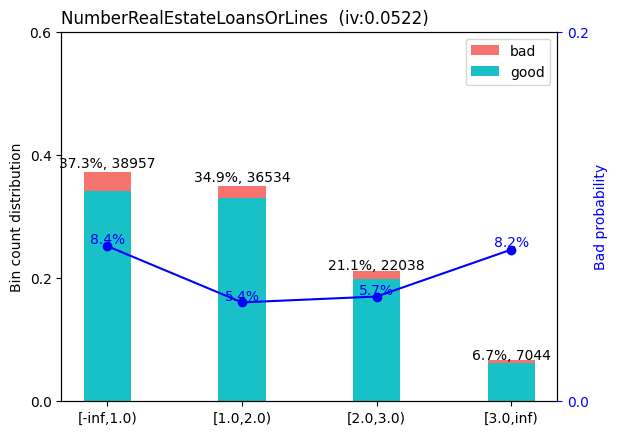

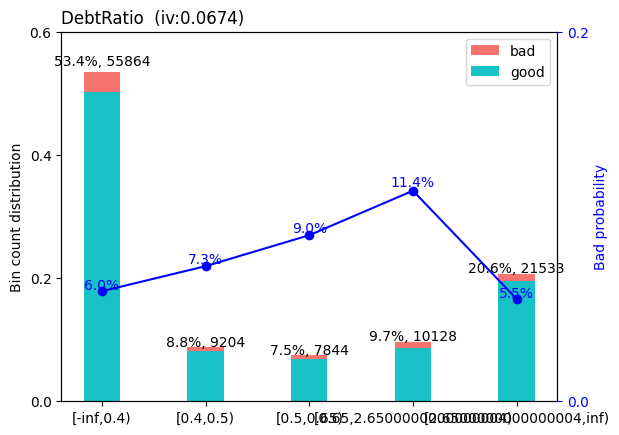

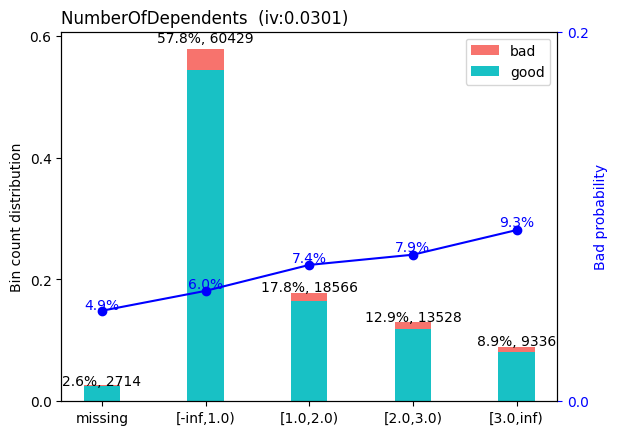

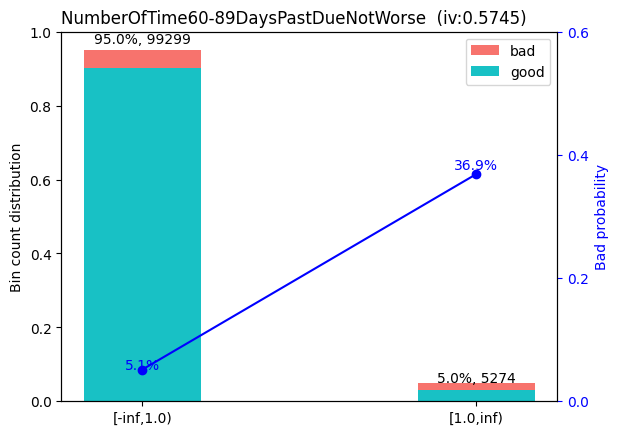

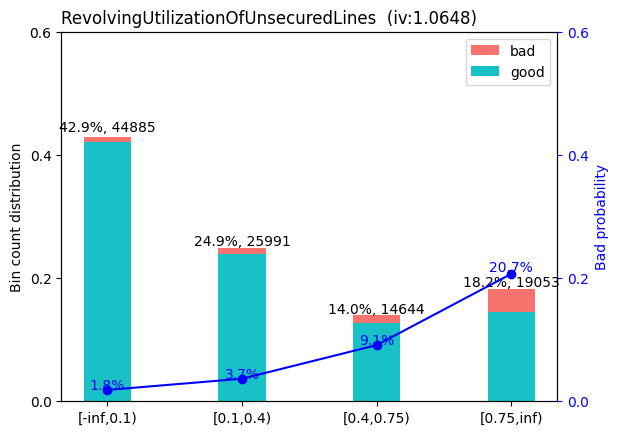

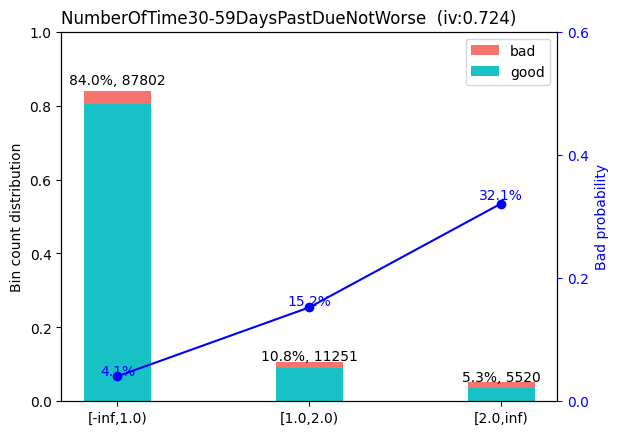

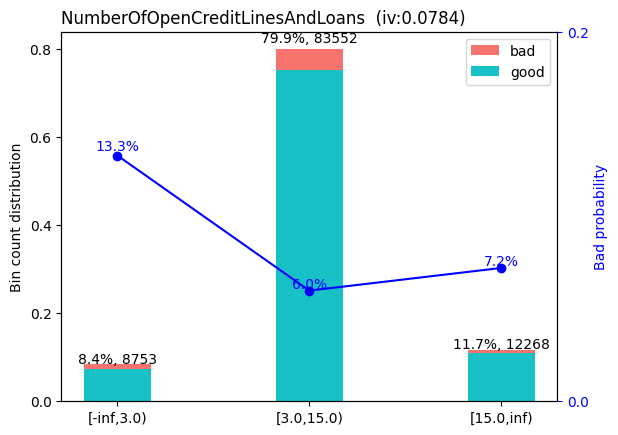

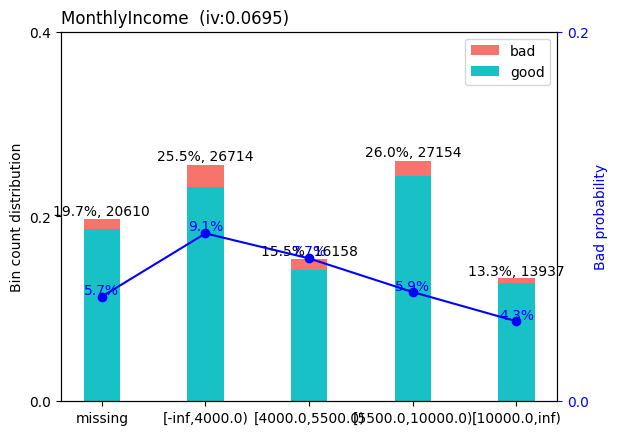

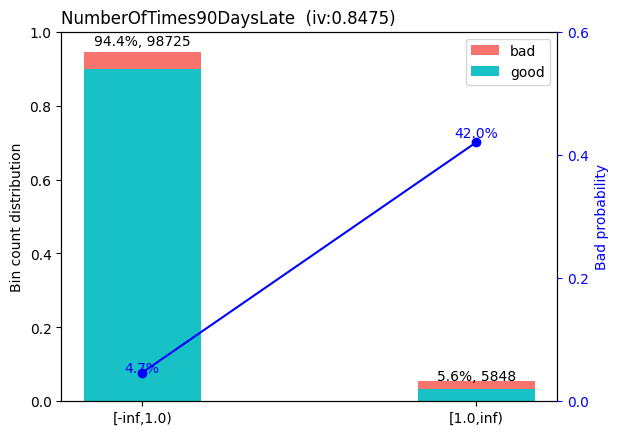

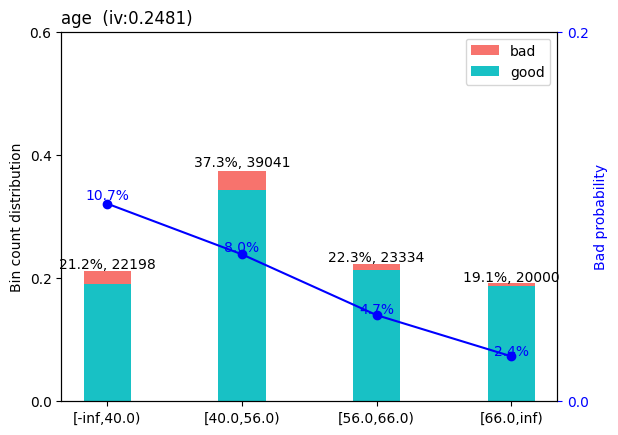

In [268]:
sc.woebin_plot(bins)

Bazując na powyższych wykresach możemy stwierdzić, które zmienne zachowują liniowość ODR. Są to:
- age,
- NumberOfTime30-59DaysPastDueNotWorse,
- RevolvingUtilizationOfUnsecuredLines,
- NumberOfTime60-89DaysPastDueNotWorse,
- NumberOfTimes90DaysLate.

Możemy natomiast całkowicie odrzucić (na bazie tego kryterium) zmienne:
- DebtRatio,
- NumberRealEstateLoansOrLines.

Pozostałe zmienne można potraktować różnie. Przy wykresie zmiennej MonthlyIncome liniowość zaburzają jedynie brakujące wartości. Brakujące wartości pojawiają się także przy zmiennej NumberOfDependents, ale w tym przypadku wpasowują się one w liniowość trendu. Pozostała zmienna NumberOfOpenCreditLinesAndLoans nie zachowuje linniowości, ale mniej definitywnie niż odrzucone DebTRatio i NumberRealEstateLoansOrLines.

#### Kryterium krokowe - selektor typujący zmienne

W tej części skorzystamy z gotowego selektora z modułu sklearn. Sprawdzimy, czy jego typy zgodzą się z naszymi oczekiwaniami.

Selektor wykorzystuje pomocniczy model regresji logistycznej i w swojej ocenie korzysta z wartości ROC AUC. Argument funkcji *direction='forward'* sprawia, że selektor dobiera kolejno najlepsze zmienne. Wpisanie zamiast tego *direction='forward'* zmieniłoby metodę działania na usuwanie zmiennych mniej ważnych. Wybór tej opcji nie powinien wpływać na wynik - możemy to jednak sprawdzić poniżej.

In [269]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SequentialFeatureSelector

model_2_1 = LogisticRegression()

selector_f = SequentialFeatureSelector(estimator=model_2_1, direction='forward', scoring='roc_auc')
selector_f.fit(train_woe, y_train)


model_2_2 = LogisticRegression()

selector_b = SequentialFeatureSelector(estimator=model_2_1, direction='backward', scoring='roc_auc')
selector_b.fit(train_woe, y_train)

SequentialFeatureSelector(direction='backward', estimator=LogisticRegression(),
                          scoring='roc_auc')

Poniżej wyświetlamy zmienne typowane przez selektor. Wybór opcji *direction* nie wpłynęło na wynik.

In [270]:
model_2_1_feats = train_woe.columns[selector_f.get_support()]
print(model_2_1_feats)
print()
model_2_2_feats = train_woe.columns[selector_b.get_support()]
print(model_2_2_feats)

Index(['NumberOfTime60-89DaysPastDueNotWorse_woe',
       'RevolvingUtilizationOfUnsecuredLines_woe',
       'NumberOfTime30-59DaysPastDueNotWorse_woe',
       'NumberOfTimes90DaysLate_woe', 'age_woe'],
      dtype='object')

Index(['NumberOfTime60-89DaysPastDueNotWorse_woe',
       'RevolvingUtilizationOfUnsecuredLines_woe',
       'NumberOfTime30-59DaysPastDueNotWorse_woe',
       'NumberOfTimes90DaysLate_woe', 'age_woe'],
      dtype='object')


##### Kryterium IV
IV (Information Value) jest miarą siły predykcyjnej danej zmiennej. Określa ją wzór:
$$
\text{IV} = \text{WOE} \cdot (\% \text{good} - \% \text{bad})
$$

Zmienne dzielimy względem IV w następujący sposób:
* silna moc predykcji: &emsp;&emsp; $\text{IV} > 0.3$,
* średnia moc predykcji: &emsp; $0.1 < \text{IV} <= 0.3$,
* słaba moc predykcji: &emsp;&emsp; $0.015 < \text{IV} <= 0.1$,
* brak mocy predykcji: &emsp;&emsp; $\text{IV} <= 0.015$.

Sprawdźmy wartości IV dla wszystkich zmiennych.

In [271]:
sc.iv(train_woe.merge(y_train, left_index=True,right_index=True, how='left'), 'SeriousDlqin2yrs')

,variable,info_value
6,RevolvingUtilizationOfUnsecuredLines_woe,1.064751
2,NumberOfTimes90DaysLate_woe,0.847455
7,NumberOfTime30-59DaysPastDueNotWorse_woe,0.724047
8,NumberOfTime60-89DaysPastDueNotWorse_woe,0.574530
0,age_woe,0.248132
9,NumberOfOpenCreditLinesAndLoans_woe,0.078420
3,MonthlyIncome_woe,0.069469
4,DebtRatio_woe,0.067394
5,NumberRealEstateLoansOrLines_woe,0.052185
1,NumberOfDependents_woe,0.030059


Silną moc predykcyjną mają zmienne:
- RevolvingUtilizationOfUnsecuredLines_woe,
- NumberOfTimes90DaysLate_woe,
- NumberOfTime30-59DaysPastDueNotWorse_woe,
- NumberOfTime60-89DaysPastDueNotWorse_woe.

Średnią moc predykcyjną przyjmuje zmienna: age_woe.

Pozostałe zmienne mają słabą moc predykcyjną (zgodnie z kryterium IV).

#### Podsumowanie - wybór zmiennych
Zarówno z kryterium IV, jak i z użytej metody krokowej (Selector Features) określiliśmy za znaczące zmienne:
- RevolvingUtilizationOfUnsecuredLines_woe,
- NumberOfTimes90DaysLate_woe,
- NumberOfTime30-59DaysPastDueNotWorse_woe,
- NumberOfTime60-89DaysPastDueNotWorse_woe,
- age.

Bazując na Information Value, możemy zauważyć, że pozostałe zmienne mają znaczny spadek mocy predykcji. W szczególności możemy uznać, że należy na pewno wykluczyć ostatnie trzy z nich: DebtRatio_woe, NumberRealEstateLoansOrLines_woe, NumberOfDependents_woe. 

Zmienne wybrane powyżej za najlepsze zachowują także monotoniczność. Na bazie tych trzech wyznaczników zostaję przy tym wyborze zmiennych.

In [272]:
final_chars = ['RevolvingUtilizationOfUnsecuredLines_woe', 'NumberOfTimes90DaysLate_woe', 'NumberOfTime30-59DaysPastDueNotWorse_woe', 'NumberOfTime60-89DaysPastDueNotWorse_woe', 'age_woe']
final_chars_arg = ['RevolvingUtilizationOfUnsecuredLines', 'NumberOfTimes90DaysLate', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'age']

Na koniec analizy zmiennych chcemy sprawdzić, czy przyjęty dla nich podział na buckety jest porządny. Wykorzystamy w tym celu miary Herfindhal Index i Population Stability Index. Służą one do oceny koncentracji klientów w każdym z bucketów (dla każdej zmiennej) oraz porównaniu stabilności bucketów między zbiorem treningowym a testowym.

Sprawdzimy jak podział na buckety wybranych zmiennych znaczących radzi sobie względem miary HHI i PSI.

#### Miara HHI
Ocenia ona koncentrację danych w pojedynczych bucketach dla danej zmiennej. Jest określona wzorem:

$$
\text{HHI} = \sum_{i=1}^{n} \left(\frac{\text{liczba obserwacji w buckecie i}}{\text{liczba wszystkich obserwacji}}\right)^2
$$

Koncentrację danych dla danej zmiennej ocenia się zgodnie z rozpiską poniżej:
- niska koncentracja: &emsp; HHI < 15%
- średnia koncentracja: &emsp; 15% ≤ HHI < 25%
- wysoka koncentracja: &emsp; HHI ≥ 25%

Sprawdźmy HHI dla wybranych zmiennych.

In [276]:
for i in final_chars_arg:
    print(f'Herfindhal Index dla zmiennej: {i}')
    display(sum(bins[i].count_distr**2))



Herfindhal Index dla zmiennej: RevolvingUtilizationOfUnsecuredLines


0.2988116836862285

Herfindhal Index dla zmiennej: NumberOfTimes90DaysLate


0.894409373309573

Herfindhal Index dla zmiennej: NumberOfTime30-59DaysPastDueNotWorse


0.7193304134584914

Herfindhal Index dla zmiennej: NumberOfTime60-89DaysPastDueNotWorse


0.9042197731127444

Herfindhal Index dla zmiennej: age


0.2708082028444668

Widzimy, że dla wszystkich zmiennych mamy wysoką koncentrację danych. Szczególnie nierównomierny podział jest na zmiennych opisujących opóźnienie w spłacie. Jest to zgodnie z poprzednimi obserwacjami i intuicją. Nie będziemy jednak w to ingerować.

#### Miara PSI
Porównuje ona stabilność rozkładów zbioru treningowego i testowego. Sprawdza ona, czy rozkład przy danym podziale na buckety nie zmienia się znacząco po przejściu ze zbioru treningowego na testowy. Miarę PSI określa wzór:
$$
\text{PSI} = \sum_{i=1}^n \left( \text{count\_distr\_train}_i - \text{count\_distr\_test}_i \right) \times \ln \left( \frac{\text{count\_distr\_train}_i}{\text{count\_distr\_test}_i} \right),
$$
gdzie:
- count_distr_train_i - procentowy udział wartości zmiennej w zbiorze treningowym,
- count_distr_test_i - procentowy udział wartości zmiennej w zbiorze testowym.



Stabilność rozkładów dla pojedynczej zmiennej ocenia się zgodnie z rozpiską:
- wysoka stabilność: &emsp; PSI < 10%
- średnia stabilność: &emsp; 10% ≤ PSI < 25%
- niska stabilność: &emsp;&emsp; 25% ≤ PSI

Sprawdźmy PSI dla wybranych zmiennych.

In [ ]:
import numpy as np

for i in final_chars_arg:
    df_stab = bins[i][['variable', 'bin', 'woe', 'count', 'count_distr']].copy()
    test_dist = test_woe[i + '_woe'].value_counts(normalize=True).rename('count_distr_test').to_frame()
    df_stab = df_stab.merge(test_dist, left_on='woe', right_index=True, how='left')
    psi_value = ((df_stab['count_distr'] - df_stab['count_distr_test']) * 
                 np.log(df_stab['count_distr'] / df_stab['count_distr_test'])).sum(skipna=True)
    print(f'Wartość PSI dla zmiennej {i} wynosi: {psi_value:8.6f}')


Wartość PSI dla zmiennej RevolvingUtilizationOfUnsecuredLines wynosi: 0.000002
Wartość PSI dla zmiennej NumberOfTimes90DaysLate wynosi: 0.000049
Wartość PSI dla zmiennej NumberOfTime30-59DaysPastDueNotWorse wynosi: 0.000012
Wartość PSI dla zmiennej NumberOfTime60-89DaysPastDueNotWorse wynosi: 0.000007
Wartość PSI dla zmiennej age wynosi: 0.000102


Widzimy, że rozkład zachowuje bardzo wysoką stabilność. 

### Budowanie modelu

Przejdźmy do budowy modelu w oparciu o regresję logistyczną.

In [ ]:
model = LogisticRegression()
model.fit(train_woe[final_chars],  y_train)

LogisticRegression()

Możemy sprawdzić wyuczone na zbiorze treningowym wartości wyrazu wolnego oraz wag kolejnych zmiennych.

In [ ]:
model.intercept_    # wyraz wolny

array([-2.59629174])

In [ ]:
model.coef_     # wagi zmiennych

array([[0.64277578, 0.53921743, 0.52754247, 0.4156615 , 0.46765076]])

Możemy w prosty sposób sprawdzić także prawdopodobieństwo bycia defaultem dla danych ze zbioru treningowego (choć jest to mniej ciekawsze niż to samo prawdopodobieństwo na zbiorze testowym).

In [ ]:
model.predict_proba(train_woe[final_chars])[:,1]


array([0.03266401, 0.0159621 , 0.10424029, ..., 0.01390754, 0.01806862,
       0.05854631])

Oceńmy model przy pomocy miary GINI.

In [ ]:
from sklearn.metrics import roc_auc_score

def gini(true_val, predicted_val):      # gini > 0.65 jest okej
    return 2 * roc_auc_score(true_val, predicted_val) - 1


In [ ]:
gini(true_val=y_train, predicted_val=model.predict_proba(train_woe[final_chars])[:,1])

0.7020394673577963

Zbudowany model uzyskuje GINI ok. 0.7 dla danych treningowych. Sprawdzimy, jak radzi sobie na danych testowych. Pokaże nam to, czy model nie jest przeuczony.

Poniżej wyświatlam prawdopodobieństwo defaultu tym razem dla danych ze zbioru testowego.

In [ ]:
model.predict_proba(test_woe[final_chars])[:, 1]

array([0.02817172, 0.0159621 , 0.05926151, ..., 0.33282884, 0.02173547,
       0.05294274])

Zanim wyliczymy GINI dla zbioru testowego, możemy porównać średnie prawdopodobieństwo predykcji defaulta (badów) na obu zbiorach (test i train).

In [ ]:
print(model.predict_proba(train_woe[final_chars])[:,1].mean())
print(model.predict_proba(test_woe[final_chars])[:,1].mean())

0.06742804744398047
0.06711248616655068


Średnie na obu zbiorach przyjmują bliskie wartości. Sprawdźmy zatem miarę GINI na danych testowych.

In [ ]:
gini(true_val=y_test, predicted_val=model.predict_proba(test_woe[final_chars])[:,1])

0.701131216491967

Miara GINI na danych testowych wynosi także ok. 0.7. Jest to bardzo dobry wynik. Podobny rząd wielkości względem GINI na zbiorze treningowym sugeruje, że model nie jest zbytnio przeuczony.

### Karta scoringowa

Ostatnim krokiem będzie przygotowanie gotowej karty scoringowej bazującej na wyuczonym i przetestowanym modelu. Całkowita wartość score dla danego klienta jest liczbą całkowitą z przedziału [0,1000]. Im większa wartość score, tym większa szansa, że będzie on dobrze spłacał kredyt.

Przyjmujemy wzór na wyliczenie wartości scoringowej (dla $i$-tej zmiennej z $j$-tego koszyka):
$$
\text{SCORE}_{i,j} = \frac{\text{PEO}}{k} - \frac{\text{PDO}}{\text{ln}(2)} \cdot (x_{i,j}^\text{WoE} \cdot \beta_i + \frac{\beta_0}{k}),
$$
gdzie:
* PEO = 500
* PDO = 20
* $k$ - liczba zmiennych
* $x_{i,j}^\text{WoE}$ - wartość WoE dla $i$-tej zmiennej z $j$-tego bucketu
* $\beta_i$ - współczynnik z regresji  logistycznej
* $\beta_0$ - wyraz wolny z regresji logistycznej

PDO (Points To Double Odds) równe 20 oznacza, że różnica 20 punktów w score między dwoma klientami przekłada się na dwukrotny wzrost lub spadek ryzyka braku spłaty zadłużenia.

PEO (Pints Equivalency Offset) równe 500 określa punkt odniesienia - wartość score klienta neutralnego. Ustalenie tej wartości na 500 jest naturalne, ze względu na to, że jest to środek skali punktowej.

Dla danego klienta całkowity score jest sumą $\text{SCORE}_{i,j}$ dla każdej rozważanej zmiennej $i$. Żeby uzyskać wartość $j$ należy sprawdzić informacje o kliencie i porównać z bucketami dla każdej ze zmiennych.

Poniżej znajduje się implementacja funkcji SCORE(i,j). Wartości i, j są indeksowane od 1. Pokazuję także parę przykładów jej użycia.

In [281]:
PEO = 500
PDO = 20
k = len(final_chars)
beta = model.coef_.flatten()
beta_0 = model.intercept_.item()


def SCORE(i, j):
    # zmiana indeksowania dla uproszczenia obslugi funkcji (zmienne i binsy numerowane od 1)
    i-=1
    j-=1
    var = final_chars_arg[i]
    
    bin_df = bins[var].reset_index(drop=True)
    if j >= len(bin_df):
        raise IndexError(f"Bin index {j} out of range for variable '{var}'.")

    row = bin_df.loc[j]     # row - wiersz bin_df odpowiadajacy danemu bin
    woe = row['woe']
    
    score = (PEO / k) - (PDO / np.log(2)) * (woe * beta[i] + beta_0 / k)
    print(f'Score dla zmiennej {var} na przedziale {row['bin']} wynosi {score}.')
    
    return score


print(SCORE(1,1))
print(SCORE(3,2))
print(SCORE(5,4))

Score dla zmiennej RevolvingUtilizationOfUnsecuredLines na przedziale [-inf,0.1) wynosi 140.0192934683332.
140.0192934683332
Score dla zmiennej NumberOfTime30-59DaysPastDueNotWorse na przedziale [1.0,2.0) wynosi 101.11424554751706.
101.11424554751706
Score dla zmiennej age na przedziale [66.0,inf) wynosi 129.3372763765709.
129.3372763765709


Poniżej przygotowałam ostateczną kartę scoringową przedstawioną w formie tabeli. Na jej bazie można łatwo odczytać podził na buckety (bin) dla każdej ze zmiennej i odczytać score z danej zmiennej dla klienta. 

In [ ]:
def build_score_table(bins, final_chars_arg, beta, beta_0, PEO=500, PDO=20, k=5):
    rows = []

    for i, var in enumerate(final_chars_arg):
        bin_df = bins[var].reset_index(drop=True)

        for _, row in bin_df.iterrows():
            woe = row['woe']
            score = (PEO / k) - (PDO / np.log(2)) * (woe * beta[i] + beta_0 / k)

            rows.append({
                'Variable': var,
                'Bin': row['bin'],
                'WoE': round(woe, 6),
                'Score': round(score, 2)
            })
        rows.append({'Variable': '', 'Bin': '', 'WoE': '','Score': ''})     # rozdzielenie zmiennych pustym wierszem

    return pd.DataFrame(rows)


score_table = build_score_table(bins, final_chars_arg, beta, beta_0)
display(score_table)


,Variable,Bin,WoE,Score
0,RevolvingUtilizationOfUnsecuredLines,"[-inf,0.1)",-1.349934,140.02
1,RevolvingUtilizationOfUnsecuredLines,"[0.1,0.4)",-0.642868,126.91
2,RevolvingUtilizationOfUnsecuredLines,"[0.4,0.75)",0.327247,108.91
3,RevolvingUtilizationOfUnsecuredLines,"[0.75,inf)",1.282062,91.2
4,,,,
5,NumberOfTimes90DaysLate,"[-inf,1.0)",-0.393408,121.1
6,NumberOfTimes90DaysLate,"[1.0,inf)",2.305976,79.11
7,,,,
8,NumberOfTime30-59DaysPastDueNotWorse,"[-inf,1.0)",-0.535714,123.14
9,NumberOfTime30-59DaysPastDueNotWorse,"[1.0,2.0)",0.911095,101.11
